In [1]:
import sys
sys.path.append("..")

import torch
from PIL import Image
from pathlib import Path

from src.dataset import PetSegmentation

In [2]:
CSV_PATH = "../data/processed/split.csv"
IMAGES = "../data/raw/oxford-iiit-pet/images"
TRIMAPS = "../data/raw/oxford-iiit-pet/annotations/trimaps"
SIZE = 256

train_ds = PetSegmentation(CSV_PATH, "train", IMAGES, TRIMAPS, SIZE)
val_ds = PetSegmentation(CSV_PATH, "val", IMAGES, TRIMAPS, SIZE)
test_ds = PetSegmentation(CSV_PATH, "test", IMAGES, TRIMAPS, SIZE)

print("Lengths:", len(train_ds), len(val_ds), len(test_ds))

Lengths: 5134 1100 1101


In [3]:
image, mask = train_ds[0]

print("Image shape:", image.shape, "| dtype:", image.dtype)
print("Mask shape:", mask.shape, "| dtype:", mask.dtype)
print("Unique mask values:", torch.unique(mask).tolist())
print(f"Image min/max: {image.min():.2f} / {image.max():.2f}")

Image shape: torch.Size([3, 256, 256]) | dtype: torch.float32
Mask shape: torch.Size([256, 256]) | dtype: torch.int64
Unique mask values: [0, 1, 2]
Image min/max: -1.98 / 2.50


In [4]:
non_rgb_idx = None
for i, stem in enumerate(train_ds.stems):
    with Image.open(Path(IMAGES) / f"{stem}.jpg") as im:
        if im.mode != "RGB":
            non_rgb_idx = i
            print("Found non-RGB image:", stem, "| original mode:", im.mode)
            break

if non_rgb_idx is not None:
    img, msk = train_ds[non_rgb_idx]
    print("Loaded shape:", img.shape, "| mask values:", torch.unique(msk).tolist())
else:
    print("No non-RGB image in the train split")

Found non-RGB image: Abyssinian_5 | original mode: RGBA
Loaded shape: torch.Size([3, 256, 256]) | mask values: [0, 1, 2]


In [5]:
from src.dataset import get_dataloaders

train_loader, val_loader, test_loader = get_dataloaders(
    CSV_PATH, IMAGES, TRIMAPS, image_size=256, batch_size=16, num_workers=0
)
print("Batches:", len(train_loader), len(val_loader), len(test_loader))

Batches: 320 69 69


d:\Dl projects\segmentation-Unet\.venv\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [6]:
images, masks = next(iter(train_loader))
print("Image batch:", images.shape, images.dtype)
print("Mask batch:", masks.shape, masks.dtype)
print("Unique mask values:", torch.unique(masks).tolist())

Image batch: torch.Size([16, 3, 256, 256]) torch.float32
Mask batch: torch.Size([16, 256, 256]) torch.int64
Unique mask values: [0, 1, 2]


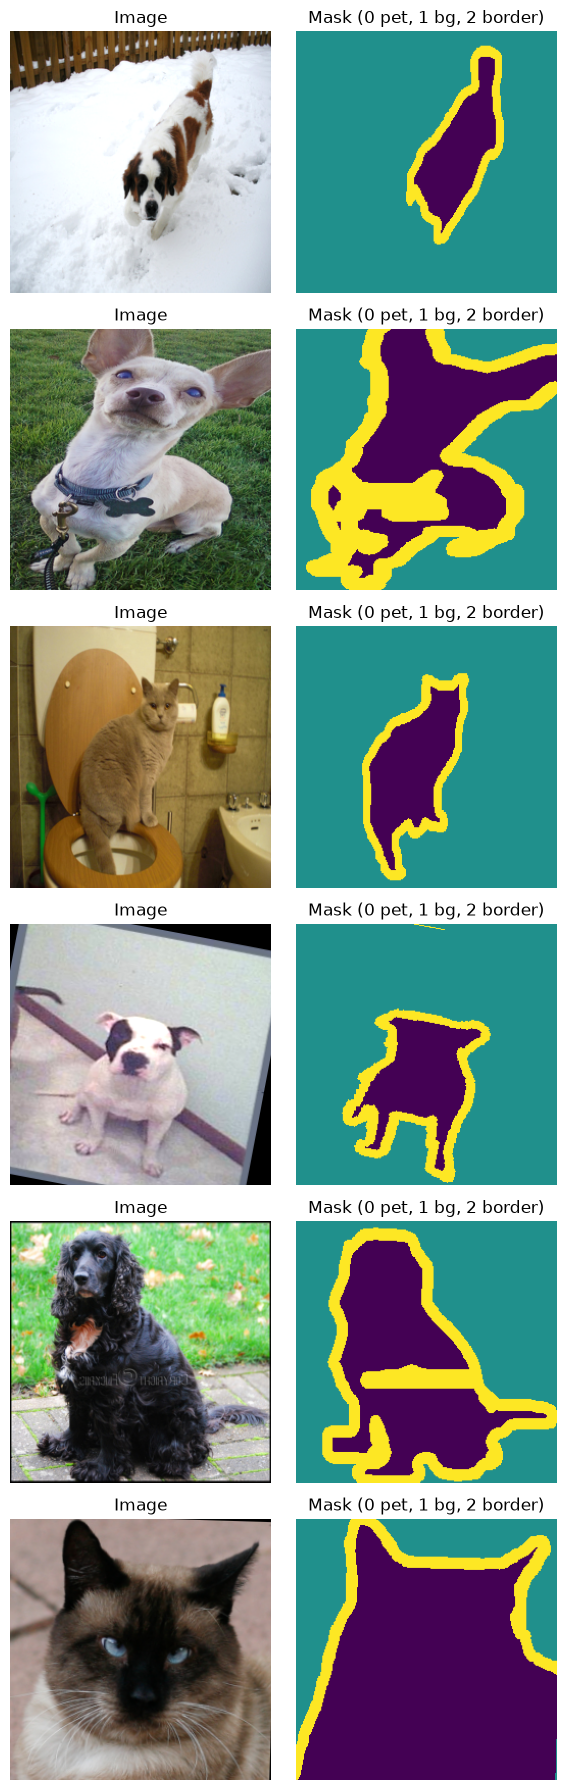

In [7]:
import matplotlib.pyplot as plt

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def denormalize(img):
    img = img * std + mean            # undo normalization
    img = img.clamp(0, 1)             # keep valid range
    return img.permute(1, 2, 0).numpy()   # (3,H,W) -> (H,W,3)

fig, axes = plt.subplots(6, 2, figsize=(6, 18))
for i in range(6):
    axes[i, 0].imshow(denormalize(images[i]))
    axes[i, 0].set_title("Image")
    axes[i, 1].imshow(masks[i].numpy(), cmap="viridis", vmin=0, vmax=2)
    axes[i, 1].set_title("Mask (0 pet, 1 bg, 2 border)")
    axes[i, 0].axis("off")
    axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

In [8]:
import time

start = time.time()
for _ in train_loader:
    pass
print(f"1 epoch, 0 workers: {time.time() - start:.1f}s")

1 epoch, 0 workers: 35.9s


In [9]:
train_loader_w, _, _ = get_dataloaders(
    CSV_PATH, IMAGES, TRIMAPS, image_size=256, batch_size=16, num_workers=2
)
start = time.time()
for _ in train_loader_w:
    pass
print(f"1 epoch, 2 workers: {time.time() - start:.1f}s")

d:\Dl projects\segmentation-Unet\.venv\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


1 epoch, 2 workers: 32.6s


d:\Dl projects\segmentation-Unet\.venv\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


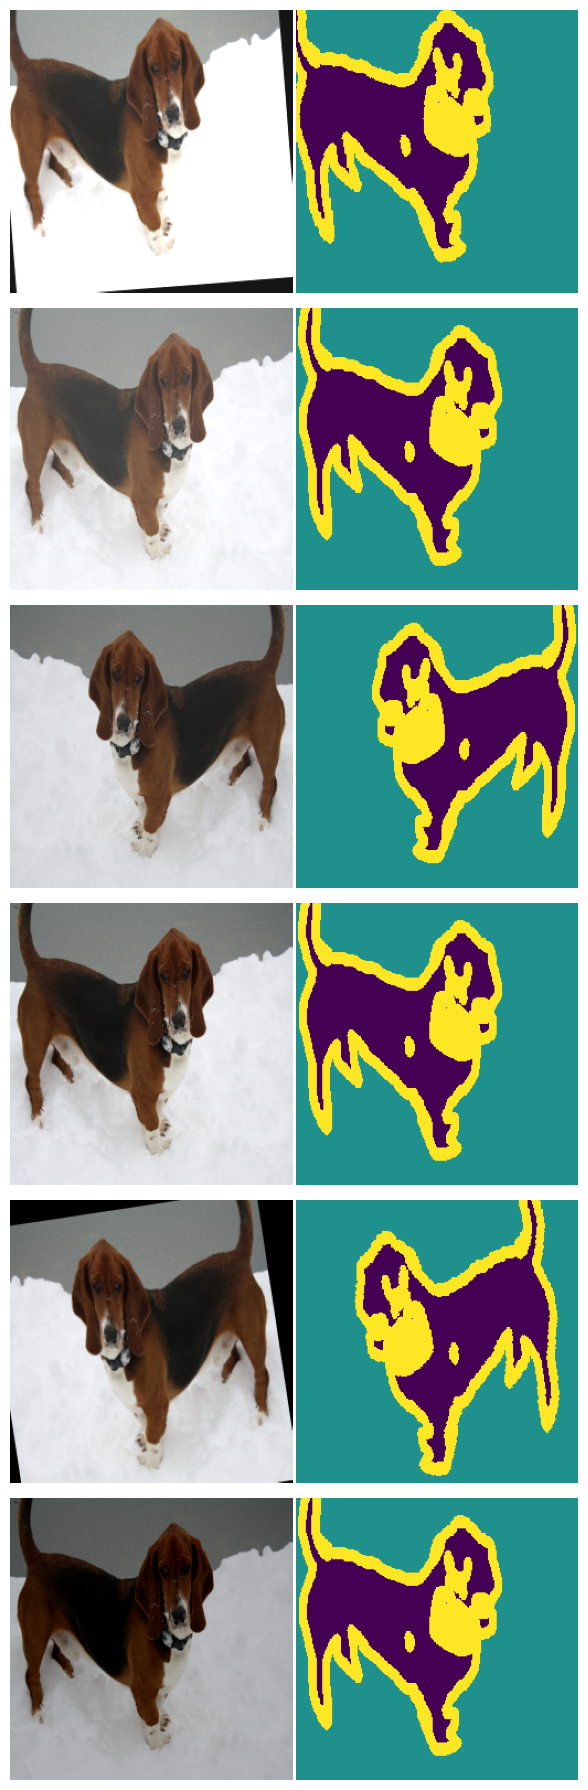

Unique mask values across the 6: [0, 1, 2]
Mask dtype: torch.int64
Val identical on repeat: True


In [10]:
import matplotlib.pyplot as plt
from src.dataset import PetSegmentation

aug_ds = PetSegmentation(CSV_PATH, "train", IMAGES, TRIMAPS, 256, augmentation=True)

fig, axes = plt.subplots(6, 2, figsize=(6, 18))
all_vals = set()
for i in range(6):
    img, msk = aug_ds[0]                       # same index every time
    all_vals.update(torch.unique(msk).tolist())
    axes[i, 0].imshow(denormalize(img))
    axes[i, 1].imshow(msk.numpy(), cmap="viridis", vmin=0, vmax=2)
    axes[i, 0].axis("off"); axes[i, 1].axis("off")
plt.tight_layout(); plt.show()

print("Unique mask values across the 6:", sorted(all_vals))
print("Mask dtype:", msk.dtype)

# val must be deterministic
a, b = val_ds[0], val_ds[0]
print("Val identical on repeat:", torch.equal(a[0], b[0]) and torch.equal(a[1], b[1]))